# 3. O juro real foi negativo depois de 2008?

No sentido comum, **juro real** é o juro descontado da inflação de preços: se a aplicação rende 10% e os preços
sobem 4%, o juro real é de 5,8% (1,10 ÷ 1,04). É negativo quando a aplicação perde para os preços.

O texto afirma que, no Brasil, ele é negativo desde 2008. Este notebook mede isso de três jeitos: em períodos de
12 meses, em janelas longas e pela taxa que o Tesouro paga a quem compra um título indexado à inflação. Em cada
um, a conta é feita com a régua usual (IPCA) e com a do texto (M2).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from juro_negativo import analise, estilo
from juro_negativo.caminhos import TRATADOS
from juro_negativo.estilo import pct

estilo.aplicar()

brasil = pd.read_parquet(TRATADOS / "brasil.parquet")
eua = pd.read_parquet(TRATADOS / "eua.parquet")
niveis = analise.niveis_do_brasil(brasil)
juro_real = analise.juro_real_12m(brasil)

## Ano a ano

A conta mais simples: a Selic acumulada de janeiro a dezembro de cada ano, descontada a inflação do mesmo ano.

De 2008 a 2025, a Selic rendeu mais que a inflação em **16 dos 18 anos**. Perdeu em 2020 (−1,7%) e em 2021
(−5,1%), os dois anos da pandemia. O melhor ano foi 2025, com juro real de 9,7%.

No período que o texto cobria quando foi escrito, de 2008 a 2022, foram 13 anos positivos em 15.

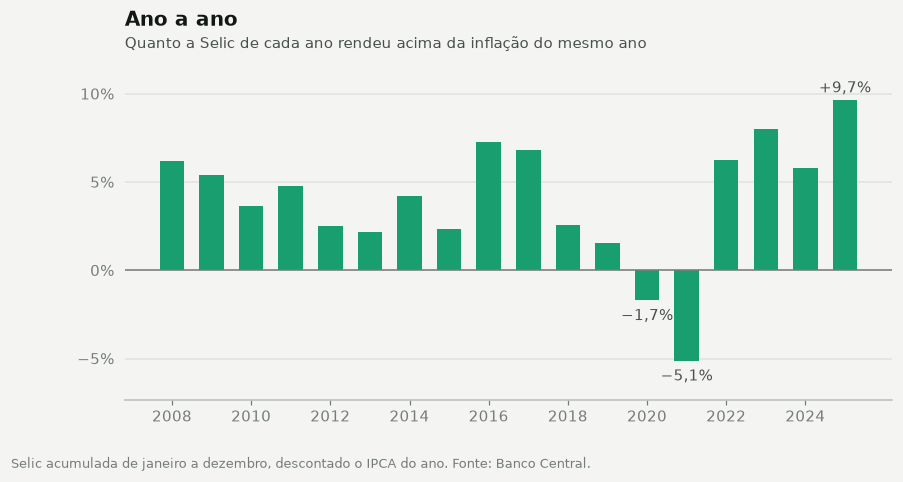

De 2008 a 2025: a Selic ganhou da inflação em 16 de 18 anos; perdeu em 2020, 2021
De 2008 a 2022: 13 de 15


,Selic,IPCA,juro real
ano,,,
2008,"+12,5%","+5,9%","+6,2%"
2009,"+9,9%","+4,3%","+5,4%"
2010,"+9,8%","+5,9%","+3,7%"
2011,"+11,6%","+6,5%","+4,8%"
2012,"+8,5%","+5,8%","+2,5%"
2013,"+8,2%","+5,9%","+2,2%"
2014,"+10,9%","+6,4%","+4,2%"
2015,"+13,3%","+10,7%","+2,4%"
2016,"+14,0%","+6,3%","+7,3%"


In [2]:
anos = analise.ano_a_ano(niveis, "selic", "ipca", desde=2008)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(anos.index, anos["acima"], width=0.62, color=estilo.cor("ipca"))
estilo.linha_de_base(ax)
for ano, valor in anos["acima"].items():
    if valor < 0 or valor == anos["acima"].max():
        ax.annotate(
            pct(valor, 1, sinal=True),
            (ano, valor),
            xytext=(0, 5 if valor > 0 else -13),
            textcoords="offset points",
            ha="center",
            fontsize=9.5,
            color=estilo.TINTA_SECUNDARIA,
        )
estilo.titulo(ax, "Ano a ano", "Quanto a Selic de cada ano rendeu acima da inflação do mesmo ano")
estilo.eixo_pct(ax.yaxis, passo=0.05)
ax.set_xticks(anos.index[::2])
ax.margins(y=0.15)
estilo.fonte(fig, "Selic acumulada de janeiro a dezembro, descontado o IPCA do ano. Fonte: Banco Central.")
plt.show()

perdeu = anos.index[anos["acima"] < 0]
print(
    f"De {anos.index[0]} a {anos.index[-1]}: a Selic ganhou da inflação em {len(anos) - len(perdeu)} de {len(anos)} anos; perdeu em {', '.join(map(str, perdeu))}"
)
ate_o_texto = anos.loc[:2022]
print(f"De 2008 a 2022: {(ate_o_texto['acima'] > 0).sum()} de {len(ate_o_texto)}")
anos.rename(columns={"selic": "Selic", "ipca": "IPCA", "acima": "juro real"}).map(lambda v: pct(v, 1, sinal=True))

## Em 12 meses

O mesmo retrato com mais detalhe: a Selic acumulada em cada período de 12 meses, mês a mês, descontada a
inflação do mesmo período. Dos 213 períodos
encerrados desde dezembro de 2008, a Selic ganhou da inflação em 191. Perdeu em 22, todos seguidos: de outubro de
2020 a julho de 2022. Foi a pandemia, com a Selic a 2% ao ano e a inflação passando de 10%. No pior ponto, em
outubro de 2021, o juro real foi de −6,6%.

O texto é de outubro de 2022, três meses depois do fim desse período.

Pela régua do M2, a história é outra: a Selic fica abaixo do crescimento do M2 em 69% dos meses desde 2008.

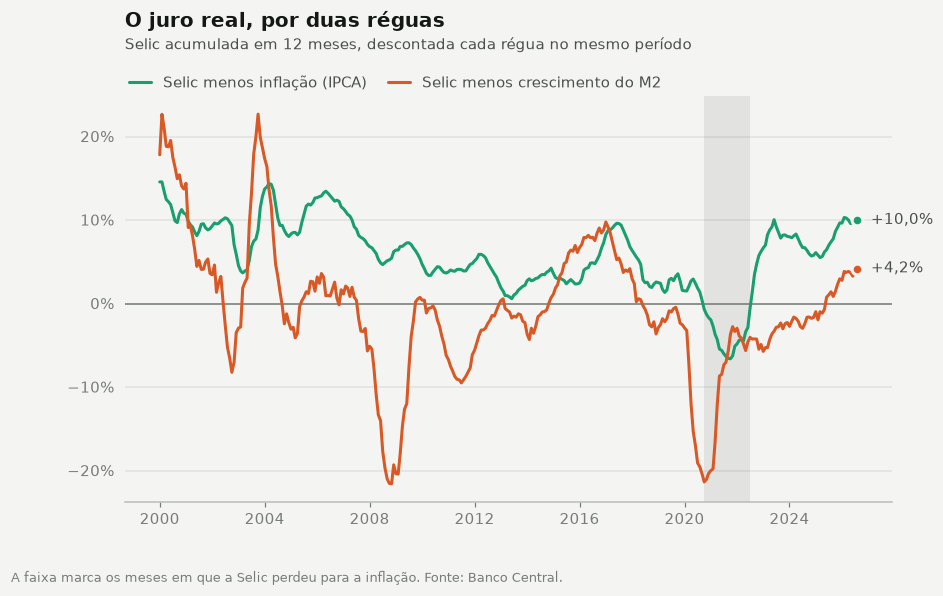

Períodos de 12 meses desde dez/2008: 213
  Selic abaixo da inflação: 22 (10/2020 a 07/2022)
  pior momento: −6,6% em 10/2021
  Selic abaixo do crescimento do M2: 69% dos meses
Em 08/2026: Selic 14,6%, IPCA 4,2%, juro real 10,0%


In [3]:
desde_2008 = juro_real.loc["2008-12-01":]
negativos = desde_2008[desde_2008["real_ipca"] < 0]

fig, ax = plt.subplots()
recorte = juro_real.loc["2000-01-01":]
ax.axvspan(negativos.index[0], negativos.index[-1], color=estilo.TINTA, alpha=0.08, lw=0)
ax.plot(recorte["real_ipca"], color=estilo.VERDE_AGUA, label="Selic menos inflação (IPCA)")
ax.plot(recorte["real_m2"], color=estilo.LARANJA, label="Selic menos crescimento do M2")
estilo.linha_de_base(ax)
estilo.titulo(
    ax,
    "O juro real, por duas réguas",
    "Selic acumulada em 12 meses, descontada cada régua no mesmo período",
    legenda=True,
)
estilo.eixo_pct(ax.yaxis)
estilo.rotular_fins(ax, lambda v: pct(v, 1, sinal=True))
estilo.fonte(fig, "A faixa marca os meses em que a Selic perdeu para a inflação. Fonte: Banco Central.")
plt.show()

print(f"Períodos de 12 meses desde dez/2008: {len(desde_2008)}")
print(f"  Selic abaixo da inflação: {len(negativos)} ({negativos.index[0]:%m/%Y} a {negativos.index[-1]:%m/%Y})")
print(f"  pior momento: {pct(desde_2008['real_ipca'].min(), 1)} em {desde_2008['real_ipca'].idxmin():%m/%Y}")
print(f"  Selic abaixo do crescimento do M2: {pct(analise.fracao_negativa(desde_2008['real_m2']))} dos meses")
ultimo = juro_real.iloc[-1]
print(
    f"Em {juro_real.index[-1]:%m/%Y}: Selic {pct(ultimo['selic_12m'], 1)}, IPCA {pct(ultimo['ipca_12m'], 1)}, juro real {pct(ultimo['real_ipca'], 1)}"
)

In [4]:
PERIODOS = {
    "1996 a 2007": ("1996-01-01", "2007-12-01"),
    "2008 até o texto": ("2008-12-01", "2022-09-01"),
    "depois do texto": ("2023-09-01", None),
}
linhas = []
for nome, (inicio, fim) in PERIODOS.items():
    trecho = juro_real.loc[inicio:fim]
    linhas.append(
        {
            "período": nome,
            "juro real médio (IPCA)": pct(trecho["real_ipca"].mean(), 1),
            "meses negativos (IPCA)": pct(analise.fracao_negativa(trecho["real_ipca"])),
            "média pelo M2": pct(trecho["real_m2"].mean(), 1),
            "meses negativos (M2)": pct(analise.fracao_negativa(trecho["real_m2"])),
        }
    )
pd.DataFrame(linhas).set_index("período")

,juro real médio (IPCA),meses negativos (IPCA),média pelo M2,meses negativos (M2)
período,,,,
1996 a 2007,"13,6%",0%,"8,1%",19%
2008 até o texto,"3,0%",13%,"−2,7%",70%
depois do texto,"7,8%",0%,"−0,0%",58%


A tabela mostra o que há de verdadeiro na percepção do texto. O juro real brasileiro **caiu muito** depois de
2008: de 13,6% ao ano, em média, para 3,0%. A queda é real. O sinal negativo, não.

("Depois do texto" considera só os períodos de 12 meses inteiramente posteriores a outubro de 2022.)

## Em janelas longas

Para evitar a escolha de datas, a mesma conta em todas as janelas de 5 e de 10 anos, começando em cada mês. A
tabela mostra em quantas delas a Selic rendeu mais que cada régua.

Em dez anos, a Selic ganhou da inflação em todas as janelas, antes e depois de 2008. Ganhou também do PIB nominal
em praticamente todas. E perdeu do M2 em 95% das janelas começadas desde 2008, e de M3 e M4 em todas.

In [5]:
linhas = []
for anos in (5, 10):
    taxas = analise.janelas(niveis, anos)
    for regua, nome in analise.REGUAS.items():
        acima = analise.descontar(taxas["selic"], taxas[regua]).dropna()
        antes, depois = acima.loc[:"2007-12-01"], acima.loc["2008-01-01":]
        linhas.append(
            {
                "janela": f"{anos} anos",
                "régua": nome,
                "começadas antes de 2008": f"{pct((antes > 0).mean())} de {len(antes)}",
                "começadas desde 2008": f"{pct((depois > 0).mean())} de {len(depois)}",
            }
        )
pd.DataFrame(linhas).set_index(["janela", "régua"])

começadas antes de 2008 começadas desde 2008
janela  régua                                                      
5 anos  Preços (IPCA)              100% de 162           99% de 165
        PIB nominal                 82% de 161           49% de 165
        Base monetária              69% de 161           62% de 165
        M1                          75% de 161           60% de 165
        M2                          65% de 161           31% de 165
        M3                           11% de 72           28% de 165
        M4                           12% de 72           26% de 165
10 anos Preços (IPCA)              100% de 162          100% de 105
        PIB nominal                 99% de 161          100% de 105
        Base monetária              71% de 161           96% de 105
        M1                          92% de 161           88% de 105
        M2                          42% de 161            5% de 105
        M3                            0% de 72            0% de 105
        M4                            0% de 72            0% de 105

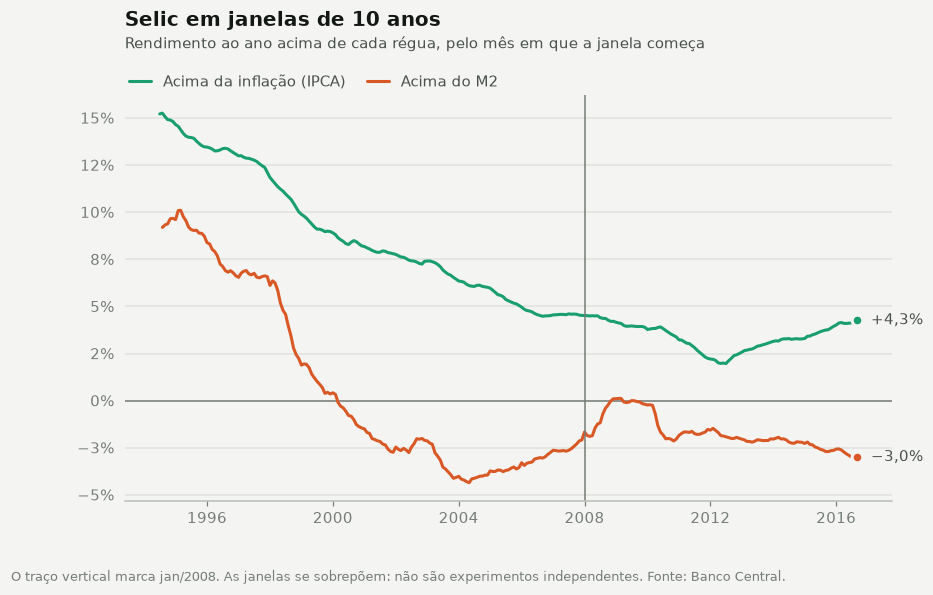

In [6]:
taxas = analise.janelas(niveis, 10)
fig, ax = plt.subplots()
ax.plot(analise.descontar(taxas["selic"], taxas["ipca"]), color=estilo.VERDE_AGUA, label="Acima da inflação (IPCA)")
ax.plot(analise.descontar(taxas["selic"], taxas["m2"]), color=estilo.LARANJA, label="Acima do M2")
estilo.linha_de_base(ax)
ax.axvline(pd.Timestamp("2008-01-01"), color=estilo.TINTA_SUAVE, lw=1)
estilo.titulo(
    ax,
    "Selic em janelas de 10 anos",
    "Rendimento ao ano acima de cada régua, pelo mês em que a janela começa",
    legenda=True,
)
estilo.eixo_pct(ax.yaxis)
estilo.rotular_fins(ax, lambda v: pct(v, 1, sinal=True))
estilo.fonte(
    fig,
    "O traço vertical marca jan/2008. As janelas se sobrepõem: não são experimentos independentes. Fonte: Banco Central.",
)
plt.show()

O gráfico acima mostra uma coisa que a frase "depois de 2008" esconde: a Selic passa a perder do M2 em janelas
começadas já em **2000**. Não há uma quebra em 2008. O que há é uma queda longa do juro real, de quase 15% para
perto de 4% ao ano, enquanto o M2 seguiu crescendo 13% ao ano.

## Todos os períodos de uma vez

Cada quadrado é um período de janeiro a janeiro: a linha é o ano de início, a coluna é o ano de fim. Azul, a
Selic rendeu mais que a régua; vermelho, menos. À esquerda, a régua dos preços: tudo azul, menos os quadrados que
terminam em 2021 e 2022. À direita, a do M2.

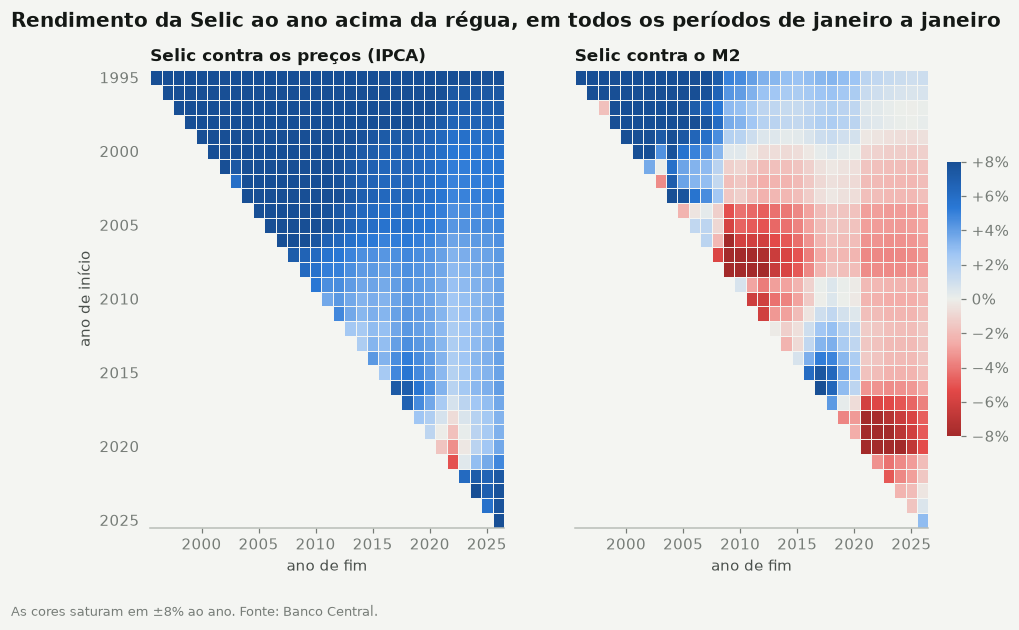

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 5.4), sharey=True)
for ax, (regua, nome) in zip(eixos, {"ipca": "Selic contra os preços (IPCA)", "m2": "Selic contra o M2"}.items()):
    matriz = analise.matriz_de_periodos(niveis, "selic", regua)
    imagem = ax.pcolormesh(
        matriz.columns,
        matriz.index,
        np.ma.masked_invalid(matriz.to_numpy()),
        cmap=estilo.DIVERGENTE,
        vmin=-0.08,
        vmax=0.08,
        edgecolors=estilo.SUPERFICIE,
        linewidth=0.6,
    )
    ax.set_title(nome, loc="left", fontsize=11, fontweight="bold")
    ax.grid(False)
    ax.set_xlabel("ano de fim")
eixos[0].invert_yaxis()  # os dois painéis dividem o eixo: os anos de início descem
eixos[0].set_ylabel("ano de início")
barra = fig.colorbar(imagem, ax=eixos, shrink=0.6, pad=0.02)
barra.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pct(v, sinal=True)))
barra.outline.set_visible(False)
fig.suptitle(
    "Rendimento da Selic ao ano acima da régua, em todos os períodos de janeiro a janeiro",
    x=0.01,
    ha="left",
    fontsize=13,
    fontweight="bold",
)
estilo.fonte(fig, "As cores saturam em ±8% ao ano. Fonte: Banco Central.")
plt.show()

## O juro real contratado

As contas acima olham para trás. Existe também o juro real que o investidor **contrata** no dia da compra: a taxa
do Tesouro IPCA+, o título público que paga a inflação mais uma taxa fixa até o vencimento.

Desde 2005, quando a série começa, essa taxa nunca foi negativa. O ponto mais baixo foi 2,7% ao ano, em agosto de
2020. Em setembro de 2022, um mês antes do texto, estava em 6,0%. Hoje está em 8,2%.

Nos Estados Unidos, o título equivalente (TIPS de dez anos) pagou taxa negativa em 45 meses: do fim de 2011 a
2013 e de 2020 a abril de 2022. Lá, o juro real negativo foi contratado em papel. Aqui, não.

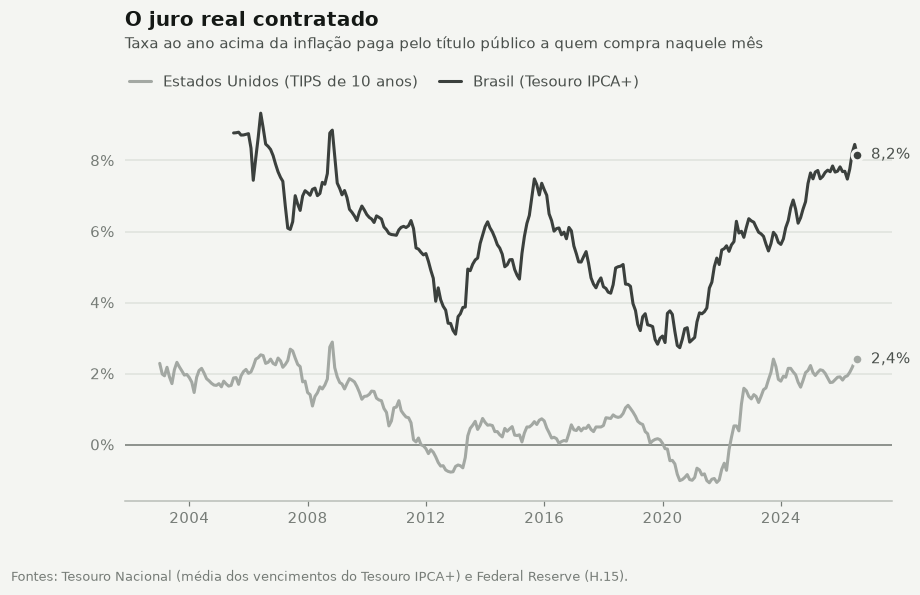

Tesouro IPCA+: mínimo de 2,7% em 08/2020; 6,0% em 09/2022; 8,2% em 08/2026
TIPS: 45 meses abaixo de zero; mínimo de −1,07% em 08/2021; 2,4% em 08/2026


In [8]:
tesouro = brasil.set_index("data")["tesouro_ipca_taxa_aa"].dropna()
tips = eua.set_index("data")["tips_10_anos_aa"].dropna()

fig, ax = plt.subplots()
ax.plot(tips, color=estilo.CINZA, label="Estados Unidos (TIPS de 10 anos)")
ax.plot(tesouro, color=estilo.GRAFITE, label="Brasil (Tesouro IPCA+)")
estilo.linha_de_base(ax)
estilo.titulo(
    ax,
    "O juro real contratado",
    "Taxa ao ano acima da inflação paga pelo título público a quem compra naquele mês",
    legenda=True,
)
estilo.eixo_pct(ax.yaxis)
estilo.rotular_fins(ax, lambda v: pct(v, 1))
estilo.fonte(fig, "Fontes: Tesouro Nacional (média dos vencimentos do Tesouro IPCA+) e Federal Reserve (H.15).")
plt.show()

print(
    f"Tesouro IPCA+: mínimo de {pct(tesouro.min(), 1)} em {tesouro.idxmin():%m/%Y}; {pct(tesouro['2022-09-01'], 1)} em 09/2022; {pct(tesouro.iloc[-1], 1)} em {tesouro.index[-1]:%m/%Y}"
)
print(
    f"TIPS: {(tips < 0).sum()} meses abaixo de zero; mínimo de {pct(tips.min(), 2)} em {tips.idxmin():%m/%Y}; {pct(tips.iloc[-1], 1)} em {tips.index[-1]:%m/%Y}"
)

## O que fica deste notebook

1. **Pela inflação de preços, o juro real brasileiro não foi negativo depois de 2008.** Foi positivo em 16 dos 18
   anos, em 191 de 213 períodos de 12 meses e em todas as janelas de dez anos.
2. **Houve um período negativo, e ele explica o momento do texto**: de outubro de 2020 a julho de 2022. O texto
   foi escrito três meses depois.
3. **O juro real caiu muito depois de 2008**, de 13,6% para 3,0% ao ano em média. Essa parte da percepção é
   verdadeira.
4. **"Juro negativo" só aparece com a régua do M2**: abaixo de zero em 69% dos meses desde 2008. E, por essa
   régua, a virada não é em 2008: janelas de dez anos começadas desde 2000 já perdem.
5. **O Tesouro IPCA+ nunca pagou taxa real negativa.** O título americano equivalente pagou, por 45 meses.